# LCC-FASD — Face Anti-Spoofing

Trains Custom CNN, ResNet18, EfficientNet-B0, MobileNetV3-Large and DeiT-Tiny on the official LCC-FASD splits (training / development / evaluation). Labels: `0 = real`, `1 = spoof`. Full images resized to 224×224, no face cropping.

Requires a GPU runtime and `LCC_FASD.zip` in `MyDrive/FaceAntiSpoofing/`. Checkpoints and results are saved to Drive; rerunning skips finished models and resumes interrupted ones.

In [ ]:
!pip -q install timm scikit-learn seaborn pandas tqdm
import torch, torchvision, timm
print('PyTorch:',torch.__version__, 'CUDA:',torch.cuda.is_available())
if torch.cuda.is_available(): print('GPU:',torch.cuda.get_device_name(0))
else: print('WARNING: switch Colab Runtime to GPU before training')

PyTorch: 2.14.1+cu130 CUDA: True
GPU: Tesla T4


## 1. Google Drive and configuration

In [1]:
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
import os, zipfile, shutil, time, json, random, hashlib

DRIVE_ROOT = Path('/content/drive/MyDrive/FaceAntiSpoofing')
DATA_ZIP = DRIVE_ROOT / 'LCC_FASD.zip'
DATA_FOLDER = DRIVE_ROOT / 'LCC_FASD'
RESULTS_DIR = DRIVE_ROOT / 'runs_lcc_fasd'
LOCAL_DATA = Path('/content/lcc_fasd_data')

MODELS = ['custom_cnn', 'resnet18', 'efficientnet_b0', 'mobilenet_v3_large', 'deit_tiny']
EPOCHS = 15
BATCH_SIZE = 32
IMAGE_SIZE = 224
LEARNING_RATE = 2e-4
WEIGHT_DECAY = 1e-4
PATIENCE = 5
LOSS_NAME = 'focal'
NUM_WORKERS = 2
SEED = 42
FORCE_RETRAIN = False

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print('Results will be saved to:', RESULTS_DIR)

ModuleNotFoundError: No module named 'google'

## 2. Dataset

In [ ]:
def find_dataset_root(base):
    base = Path(base)
    candidates = [base] + [p.parent for p in base.rglob('LCC_FASD_training') if p.is_dir()]
    for root in candidates:
        if all((root / x).is_dir() for x in ['LCC_FASD_training', 'LCC_FASD_development', 'LCC_FASD_evaluation']):
            return root
    raise FileNotFoundError(f'Expected LCC-FASD splits not found below {base}. Check ZIP/folder layout.')

if DATA_ZIP is not None:
    if not Path(DATA_ZIP).is_file():
        raise FileNotFoundError(f'Upload the dataset ZIP to Google Drive first: {DATA_ZIP}')
    LOCAL_DATA.mkdir(parents=True, exist_ok=True)
    marker = LOCAL_DATA / '.extraction_complete'
    zip_sig = f'{Path(DATA_ZIP).stat().st_size}:{Path(DATA_ZIP).stat().st_mtime_ns}'
    if not marker.exists() or marker.read_text() != zip_sig:
        shutil.rmtree(LOCAL_DATA, ignore_errors=True)
        LOCAL_DATA.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(DATA_ZIP) as z:
            for info in z.infolist():
                dest = (LOCAL_DATA / info.filename).resolve()
                if not dest.is_relative_to(LOCAL_DATA.resolve()):
                    raise ValueError(f'Unsafe zip path: {info.filename}')
            z.extractall(LOCAL_DATA)
        marker.write_text(zip_sig)
    DATA_ROOT = find_dataset_root(LOCAL_DATA)
else:
    DATA_ROOT = find_dataset_root(DATA_FOLDER)
print('Using dataset:', DATA_ROOT)

Using dataset: /content/lcc_fasd_data


## 3. Splits and class distribution

train: real=1223, spoof=7076 (folder=/content/lcc_fasd_data/LCC_FASD_training)
val: real=405, spoof=2543 (folder=/content/lcc_fasd_data/LCC_FASD_development)
test: real=314, spoof=7266 (folder=/content/lcc_fasd_data/LCC_FASD_evaluation)


,split,real,spoof,total
0,train,1223,7076,8299
1,val,405,2543,2948
2,test,314,7266,7580


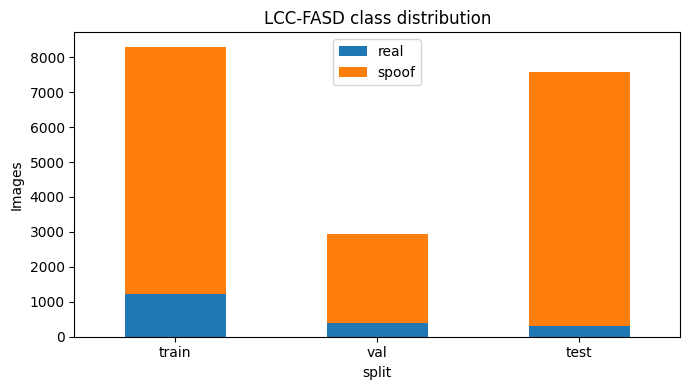

In [ ]:
from collections import Counter
import pandas as pd
EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

def image_files(folder):
    return sorted(p for p in folder.rglob('*') if p.is_file() and p.suffix.lower() in EXTS)

def collect_split(root, split):
    root = Path(root)
    part = {'train':'LCC_FASD_training', 'val':'LCC_FASD_development', 'test':'LCC_FASD_evaluation'}[split]
    folder = root / part
    if not folder.is_dir():
        raise FileNotFoundError(f'Missing {split} directory: {folder}')
    rows = []
    for cls, y in [('real', 0), ('spoof', 1)]:
        class_dir = folder / cls
        if class_dir.is_dir():
            rows.extend((p, y) for p in image_files(class_dir))
    for p in sorted(folder.iterdir()):
        if not p.is_file() or p.suffix.lower() not in EXTS:
            continue
        filename = p.name.lower()
        if filename.startswith('real'):
            rows.append((p, 0))
        elif filename.startswith('spoof'):
            rows.append((p, 1))
        else:
            raise ValueError(f'Cannot infer {split} label from filename: {p.name}')
    counts = Counter(y for _, y in rows)
    print(f'{split}: real={counts[0]}, spoof={counts[1]} (folder={folder})')
    if not rows or counts[0] == 0 or counts[1] == 0:
        print('Folder contents:', [(p.name, 'dir' if p.is_dir() else 'file') for p in list(folder.iterdir())[:20]])
        raise ValueError(f'{split}: missing images or one of the real/spoof classes. Check folder listing above.')
    return rows

SPLITS = {s: collect_split(DATA_ROOT,s) for s in ['train','val','test']}
all_paths = [str(p.resolve()) for rows in SPLITS.values() for p,_ in rows]
assert len(all_paths) == len(set(all_paths)), 'Overlapping file paths across splits'
split_table = pd.DataFrame([{'split':s,'real':sum(y==0 for _,y in rows),'spoof':sum(y==1 for _,y in rows),'total':len(rows)} for s,rows in SPLITS.items()])
display(split_table)
split_table.to_csv(RESULTS_DIR/'split_counts.csv',index=False)
import matplotlib.pyplot as plt
ax=split_table.set_index('split')[['real','spoof']].plot(kind='bar',stacked=True,figsize=(7,4))
ax.set_title('LCC-FASD class distribution');ax.set_ylabel('Images');plt.xticks(rotation=0);plt.tight_layout()
plt.savefig(RESULTS_DIR/'split_distribution.png',dpi=160);plt.show()


TRAIN dataset:
REAL: 1223 | SPOOF: 7076


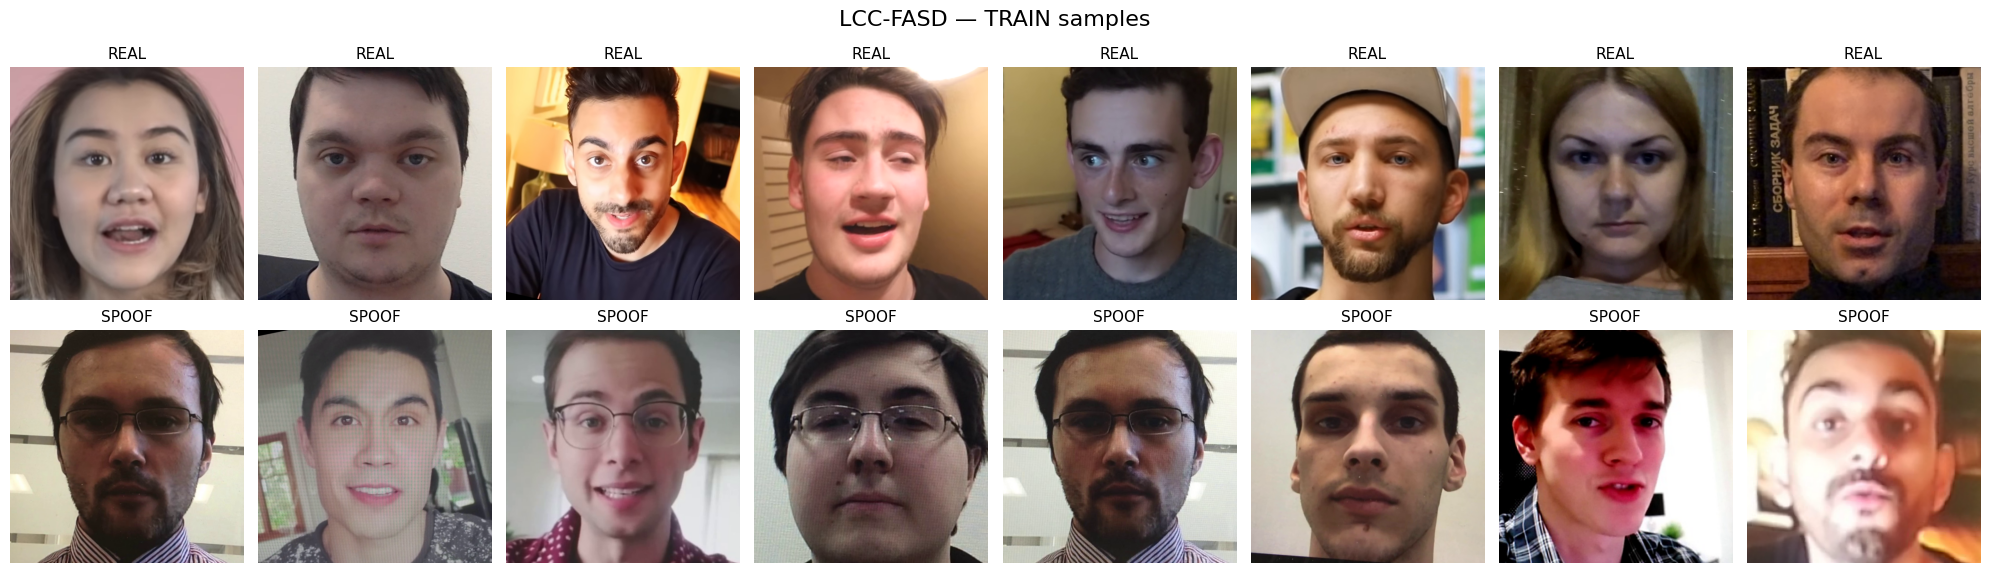

In [15]:

import random
import matplotlib.pyplot as plt
from PIL import Image

def show_dataset_samples(split="train", n_per_class=8, seed=42):
    samples = SPLITS[split]

    real_images = [path for path, label in samples if int(label) == 0]
    spoof_images = [path for path, label in samples if int(label) == 1]

    print(f"{split.upper()} dataset:")
    print(f"REAL: {len(real_images)} | SPOOF: {len(spoof_images)}")

    rng = random.Random(seed)

    fig, axes = plt.subplots(
        2, n_per_class,
        figsize=(2.5 * n_per_class, 6),
        squeeze=False
    )

    for row, (images, name) in enumerate([
        (real_images, "REAL"),
        (spoof_images, "SPOOF")
    ]):
        selected = rng.sample(images, min(n_per_class, len(images)))

        for col, ax in enumerate(axes[row]):
            ax.axis("off")

            if col >= len(selected):
                continue

            path = selected[col]

            try:
                with Image.open(path) as img:
                    ax.imshow(img.convert("RGB"))
                ax.set_title(name, fontsize=11)
            except Exception as e:
                ax.set_title("Error loading image")
                print(path, e)

    plt.suptitle(f"LCC-FASD — {split.upper()} samples", fontsize=16)
    plt.tight_layout()
    plt.show()

show_dataset_samples(split="train", n_per_class=8)


VAL dataset:
REAL: 405 | SPOOF: 2543


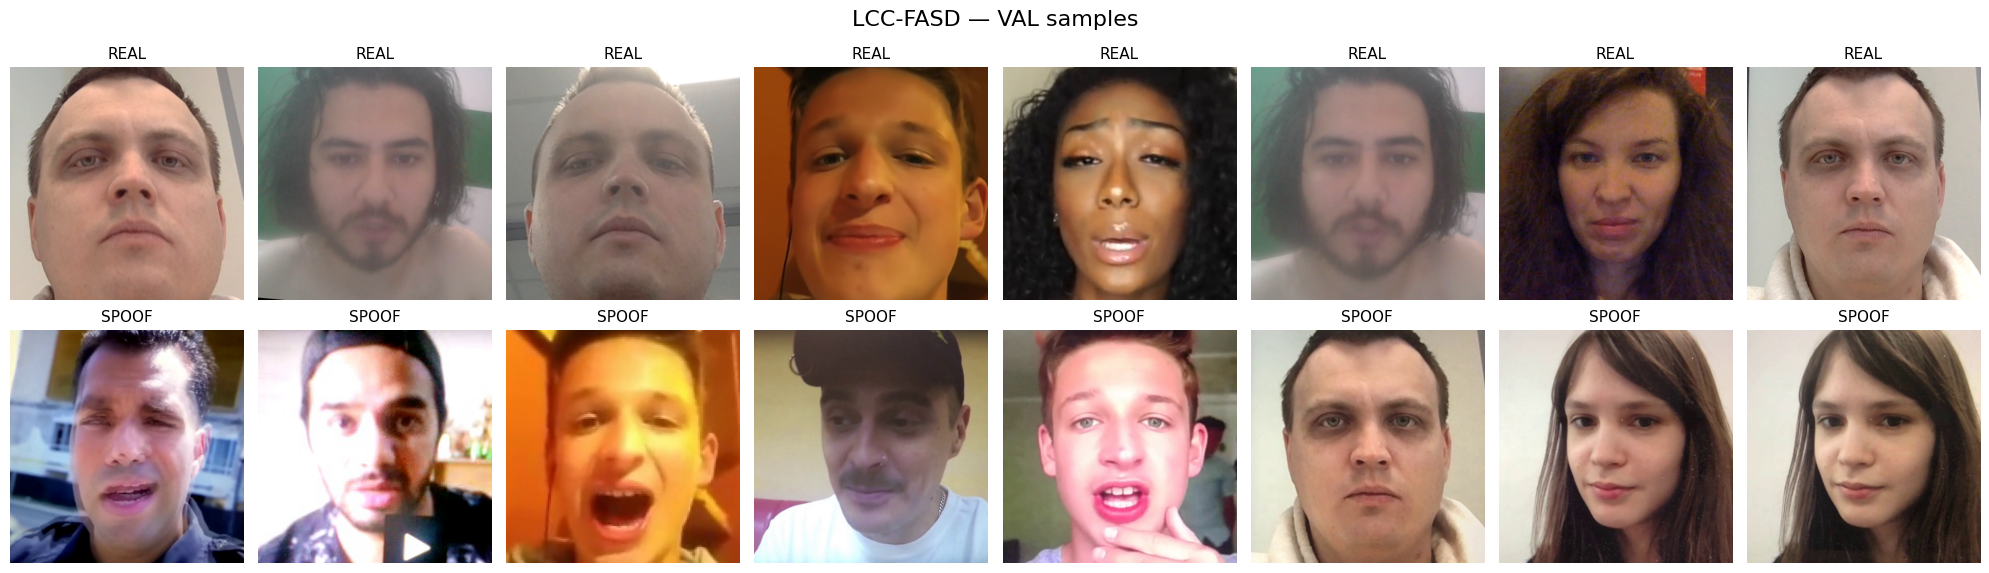

In [16]:
show_dataset_samples(split="val", n_per_class=8, seed=123)

TEST dataset:
REAL: 314 | SPOOF: 7266


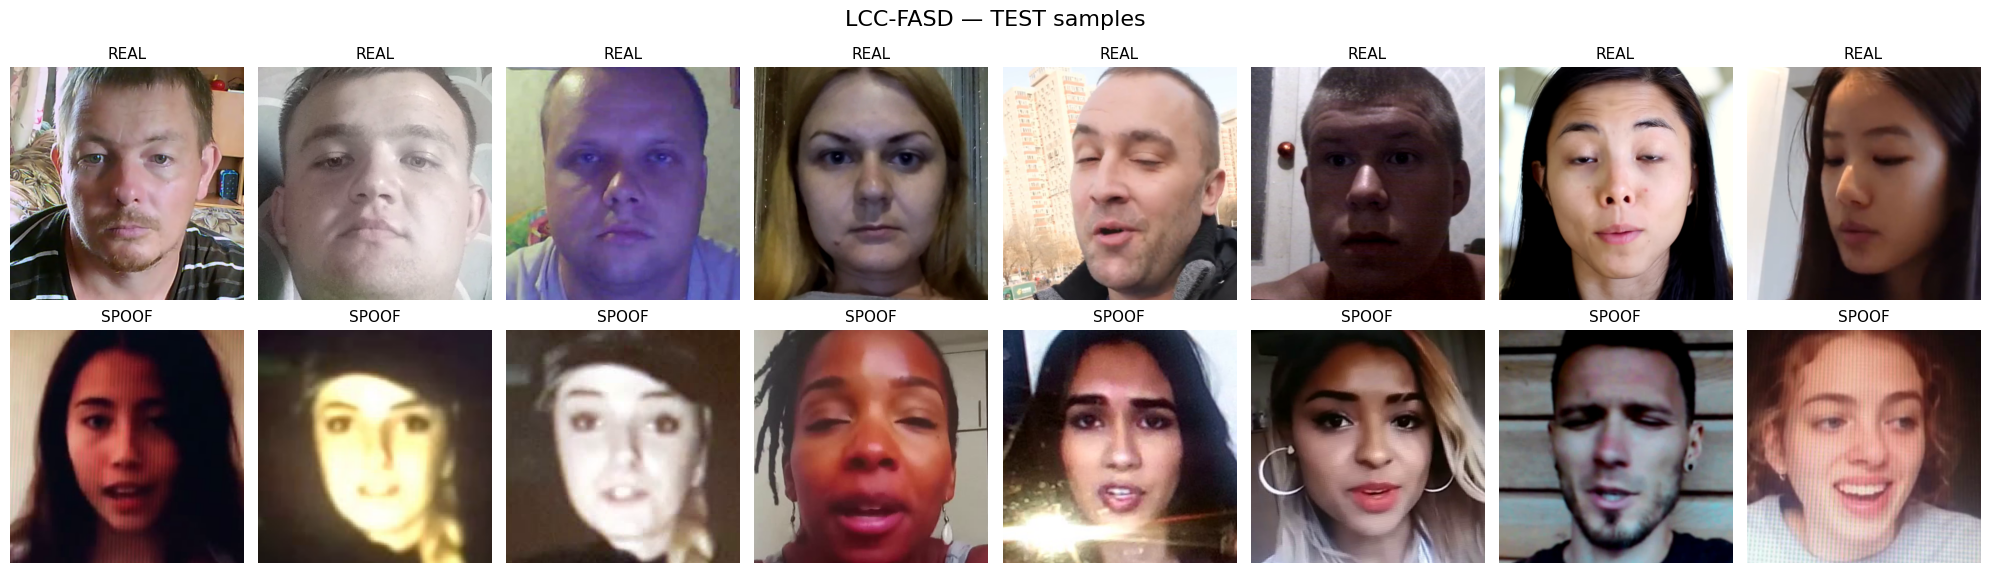

In [17]:
show_dataset_samples(split="test", n_per_class=8, seed=456)

## 4. Data loaders and augmentation

In [ ]:
import numpy as np
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
seed_everything(SEED)

class FASImages(Dataset):
    def __init__(self, rows, train=False):
        self.rows = rows
        tf = [transforms.Resize((IMAGE_SIZE,IMAGE_SIZE))]
        if train:
            tf += [transforms.RandomHorizontalFlip(), transforms.ColorJitter(brightness=.15,contrast=.15,saturation=.1)]
        tf += [transforms.ToTensor(),transforms.Normalize([.485,.456,.406],[.229,.224,.225])]
        self.tf = transforms.Compose(tf)
    def __len__(self): return len(self.rows)
    def __getitem__(self,i):
        path,label = self.rows[i]
        with Image.open(path) as img: image = self.tf(img.convert('RGB'))
        return image, torch.tensor(label,dtype=torch.float32)

def make_loaders():
    return {s:DataLoader(FASImages(rows,train=(s=='train')),batch_size=BATCH_SIZE,shuffle=(s=='train'),num_workers=NUM_WORKERS,pin_memory=torch.cuda.is_available(),persistent_workers=NUM_WORKERS>0) for s,rows in SPLITS.items()}
LOADERS=make_loaders()
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)

Device: cuda


## 5. Models and loss

`custom_cnn` is trained from scratch, the others start from ImageNet weights. Focal loss with class weights handles the real/spoof imbalance.

In [ ]:
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models

class CustomCNN(nn.Module):
    def __init__(self):
        super().__init__()
        layers=[]; c=3
        for d in [32,64,128,192]:
            layers += [nn.Conv2d(c,d,3,padding=1),nn.BatchNorm2d(d),nn.ReLU(inplace=True),nn.MaxPool2d(2)]
            c=d
        self.features=nn.Sequential(*layers, nn.AdaptiveAvgPool2d(1))
        self.classifier=nn.Sequential(nn.Flatten(),nn.Dropout(.3),nn.Linear(192,1))
    def forward(self,x):return self.classifier(self.features(x)).flatten()

def build_model(name, pretrained=True):
    if name=='custom_cnn': return CustomCNN()
    if name=='resnet18':
        m=models.resnet18(weights=models.ResNet18_Weights.DEFAULT if pretrained else None)
        m.fc=nn.Linear(m.fc.in_features,1)
    elif name=='efficientnet_b0':
        m=models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT if pretrained else None)
        m.classifier[-1]=nn.Linear(m.classifier[-1].in_features,1)
    elif name=='mobilenet_v3_large':
        m=models.mobilenet_v3_large(weights=models.MobileNet_V3_Large_Weights.DEFAULT if pretrained else None)
        m.classifier[-1]=nn.Linear(m.classifier[-1].in_features,1)
    elif name=='deit_tiny':
        m=timm.create_model('deit_tiny_patch16_224', pretrained=pretrained, num_classes=1)
    else: raise ValueError(name)
    return m

class BinaryFocal(nn.Module):
    def __init__(self,pos_weight,gamma=2):
        super().__init__();self.pw=float(pos_weight);self.gamma=gamma
    def forward(self,logits,targets):
        bce=F.binary_cross_entropy_with_logits(logits,targets,reduction='none')
        pt=torch.exp(-bce)
        wt=torch.where(targets>0.5,self.pw,1.0)
        return (wt*(1-pt).pow(self.gamma)*bce).mean()

nreal=sum(y==0 for _,y in SPLITS['train']); nspoof=sum(y==1 for _,y in SPLITS['train'])
POS_WEIGHT=nreal/nspoof

def make_loss():
    if LOSS_NAME=='focal':return BinaryFocal(POS_WEIGHT)
    if LOSS_NAME=='bce':return nn.BCEWithLogitsLoss(pos_weight=torch.tensor(POS_WEIGHT,device=DEVICE))
    raise ValueError('LOSS_NAME must be focal or bce')
print('Train real:',nreal,'spoof:',nspoof,'positive class weight:',round(POS_WEIGHT,4))

Train real: 1223 spoof: 7076 positive class weight: 0.1728


## 6. Metrics and threshold

The threshold is chosen on the development split (minimum ACER) and then fixed for the test split.

In [ ]:
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,roc_curve,precision_recall_curve,confusion_matrix)
from tqdm.auto import tqdm
import seaborn as sns

@torch.no_grad()
def evaluate(model,loader,criterion=None):
    model.eval(); yy=[]; pp=[]; loss_sum=0; n=0
    for x,y in loader:
        x=x.to(DEVICE,non_blocking=True);y=y.to(DEVICE,non_blocking=True)
        with torch.autocast(device_type=DEVICE.type,enabled=DEVICE.type=='cuda'):
            logits=model(x).reshape(-1)
            loss=criterion(logits,y) if criterion else None
        if loss is not None: loss_sum+=float(loss.item())*len(y)
        n+=len(y)
        yy.extend(y.cpu().numpy());pp.extend(logits.float().sigmoid().cpu().numpy())
    return np.asarray(yy,dtype=int),np.asarray(pp),loss_sum/n if criterion else None

def metrics_at(y,p,threshold):
    pred=(p>=threshold).astype(int)
    tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    apcer=fn/(tp+fn) if tp+fn else float('nan')
    bpcer=fp/(tn+fp) if tn+fp else float('nan')
    result=dict(accuracy=accuracy_score(y,pred),precision=precision_score(y,pred,zero_division=0),
        recall=recall_score(y,pred,zero_division=0),f1=f1_score(y,pred,zero_division=0),
        roc_auc=roc_auc_score(y,p) if len(np.unique(y))==2 else float('nan'),
        apcer=apcer,bpcer=bpcer,acer=(apcer+bpcer)/2,threshold=float(threshold),n=len(y),
        tn=int(tn),fp=int(fp),fn=int(fn),tp=int(tp))
    return result

def choose_threshold(y,p):
    scores=np.sort(np.unique(p))
    thresholds=np.r_[0.0,(scores[:-1]+scores[1:])/2,1.0]
    fpr,tpr,roc_t=roc_curve(y,p)
    balanced=tpr-fpr
    k=int(np.argmax(balanced))
    t=roc_t[k]
    if not np.isfinite(t): t=1.0
    return float(np.clip(t,0,1))

CONFIG = dict(models=MODELS,epochs=EPOCHS,batch_size=BATCH_SIZE,image_size=IMAGE_SIZE,lr=LEARNING_RATE,
              weight_decay=WEIGHT_DECAY,patience=PATIENCE,loss=LOSS_NAME,seed=SEED,
              n_train=len(SPLITS['train']),n_val=len(SPLITS['val']),n_test=len(SPLITS['test']))
config_hash=hashlib.sha256(json.dumps(CONFIG,sort_keys=True).encode()).hexdigest()[:12]
print('Configuration:',CONFIG,'\nconfig ID:',config_hash)

Configuration: {'models': ['custom_cnn', 'resnet18', 'efficientnet_b0', 'mobilenet_v3_large', 'deit_tiny'], 'epochs': 15, 'batch_size': 32, 'image_size': 224, 'lr': 0.0002, 'weight_decay': 0.0001, 'patience': 5, 'loss': 'focal', 'seed': 42, 'n_train': 8299, 'n_val': 2948, 'n_test': 7580} 
config ID: faa72e1d05da


## 7. Training

In [8]:
import csv

def save_json(path,obj):
    with open(path,'w') as f: json.dump(obj,f,indent=2,default=lambda v: float(v) if isinstance(v,np.floating) else int(v) if isinstance(v,np.integer) else str(v))

def train_one(name):
    out=RESULTS_DIR/name;out.mkdir(parents=True,exist_ok=True)
    done=out/'test_metrics.json'; current_config=out/'run_config.json'
    if current_config.exists():
        old=json.loads(current_config.read_text())
        if old['config_id']!=config_hash:
            raise RuntimeError(f'Configuration changed for {name}. Set a new RESULTS_DIR (recommended) or remove its old run folder.')
    if done.exists() and not FORCE_RETRAIN:
        print(f'SKIP {name}: results already saved to Drive')
        return json.loads(done.read_text())
    save_json(current_config,{'config_id':config_hash,'config':CONFIG,'model':name})
    seed_everything(SEED)
    model=build_model(name,pretrained=True).to(DEVICE)
    criterion=make_loss();opt=torch.optim.AdamW(model.parameters(),lr=LEARNING_RATE,weight_decay=WEIGHT_DECAY)
    scaler=torch.amp.GradScaler('cuda',enabled=DEVICE.type=='cuda')
    start=0;best_auc=-float('inf');bad=0;history=[]
    latest=out/'latest.pt';best_file=out/'best.pt'
    if latest.exists() and not FORCE_RETRAIN:
        state=torch.load(latest,map_location=DEVICE,weights_only=False)
        model.load_state_dict(state['model']);opt.load_state_dict(state['optimizer']);scaler.load_state_dict(state['scaler'])
        start=state['epoch']+1;best_auc=state['best_auc'];bad=state['bad'];history=state['history']
        print(f'RESUME {name} from epoch {start+1}')
    else:print(f'NEW {name}')
    for epoch in range(start,EPOCHS):
        model.train();running=0;n=0;train_correct=0
        for x,y in tqdm(LOADERS['train'],desc=f'{name} | Epoch {epoch+1}/{EPOCHS}',leave=False):
            x=x.to(DEVICE,non_blocking=True); y=y.to(DEVICE,non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type,enabled=DEVICE.type=='cuda'):
                logits=model(x).reshape(-1);loss=criterion(logits,y)
            scaler.scale(loss).backward();scaler.step(opt);scaler.update()
            running+=loss.item()*len(y);n+=len(y)
            train_correct+=int(((logits.detach().sigmoid()>=.5)==y.bool()).sum().item())
        vy,vp,v_loss=evaluate(model,LOADERS['val'],criterion)
        val_auc=roc_auc_score(vy,vp)
        vt=choose_threshold(vy,vp);vm=metrics_at(vy,vp,vt)
        entry={'epoch':epoch+1,'train_loss':running/n,'train_accuracy':train_correct/n,
               'val_loss':v_loss,'val_accuracy':vm['accuracy'],'val_auc':val_auc,
               'val_acer':vm['acer'],'val_threshold':vt}
        history.append(entry)
        if val_auc>best_auc+1e-6:
            best_auc=val_auc;bad=0
            torch.save({'model':model.state_dict(),'epoch':epoch,'val_auc':val_auc},best_file)
        else:bad+=1
        torch.save({'model':model.state_dict(),'optimizer':opt.state_dict(),'scaler':scaler.state_dict(),
                    'epoch':epoch,'best_auc':best_auc,'bad':bad,'history':history},latest)
        pd.DataFrame(history).to_csv(out/'history.csv',index=False)
        print(f' {name} {epoch+1:2d}: train loss {entry["train_loss"]:.4f}  val loss {v_loss:.4f}  val AUC {val_auc:.4f}  val ACER {vm["acer"]:.4f}')
        if bad>=PATIENCE:
            print('Early stopping');break
    if not best_file.exists(): raise RuntimeError('No best checkpoint; training did not run successfully')
    state=torch.load(best_file,map_location=DEVICE,weights_only=False);model.load_state_dict(state['model'])
    vy,vp,_=evaluate(model,LOADERS['val'],criterion)
    threshold=choose_threshold(vy,vp)
    ty,tp,_=evaluate(model,LOADERS['test'],criterion)
    test=metrics_at(ty,tp,threshold)
    test.update(model=name,best_epoch=state['epoch']+1,parameters=sum(p.numel() for p in model.parameters()))
    pd.DataFrame({'label':ty,'spoof_probability':tp,'predicted_label':(tp>=threshold).astype(int),
                  'image_path':[str(p) for p,_ in SPLITS['test']]}).to_csv(out/'test_predictions.csv',index=False)
    save_json(out/'test_metrics.json',test)
    save_json(out/'threshold.json',{'threshold':threshold,'selected_on':'development','criterion':'minimum ACER'})
    return test

RESULTS=[]
for model_name in MODELS:
    try:
        result=train_one(model_name)
        RESULTS.append(result)
        print('DONE',model_name,'AUC:',round(result['roc_auc'],4),'ACER:',round(result['acer'],4))
    except Exception as exc:
        print(f'ERROR in {model_name}: {type(exc).__name__}: {exc}')
        print('Fix issue and rerun: completed runs will be skipped, unfinished runs resumed.')
        raise
print('All requested models completed.')

SKIP custom_cnn: results already saved to Drive
DONE custom_cnn AUC: 0.9005 ACER: 0.1614
SKIP resnet18: results already saved to Drive
DONE resnet18 AUC: 0.9661 ACER: 0.0852
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 149MB/s]


RESUME efficientnet_b0 from epoch 9


efficientnet_b0 | Epoch 9/15:   0%|          | 0/260 [00:00<?, ?it/s]

 efficientnet_b0  9: train loss 0.0008  val loss 0.0223  val AUC 0.9794  val ACER 0.0273
Early stopping
DONE efficientnet_b0 AUC: 0.9817 ACER: 0.0693
Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 152MB/s]


... (55 outputs left out)

deit_tiny | Epoch 13/15:   0%|          | 0/260 [00:00<?, ?it/s]

 deit_tiny 13: train loss 0.0048  val loss 0.0331  val AUC 0.9789  val ACER 0.0729


deit_tiny | Epoch 14/15:   0%|          | 0/260 [00:00<?, ?it/s]

 deit_tiny 14: train loss 0.0039  val loss 0.0501  val AUC 0.9742  val ACER 0.0839
Early stopping
DONE deit_tiny AUC: 0.9694 ACER: 0.1031
All requested models completed.


## 8. Per-model plots

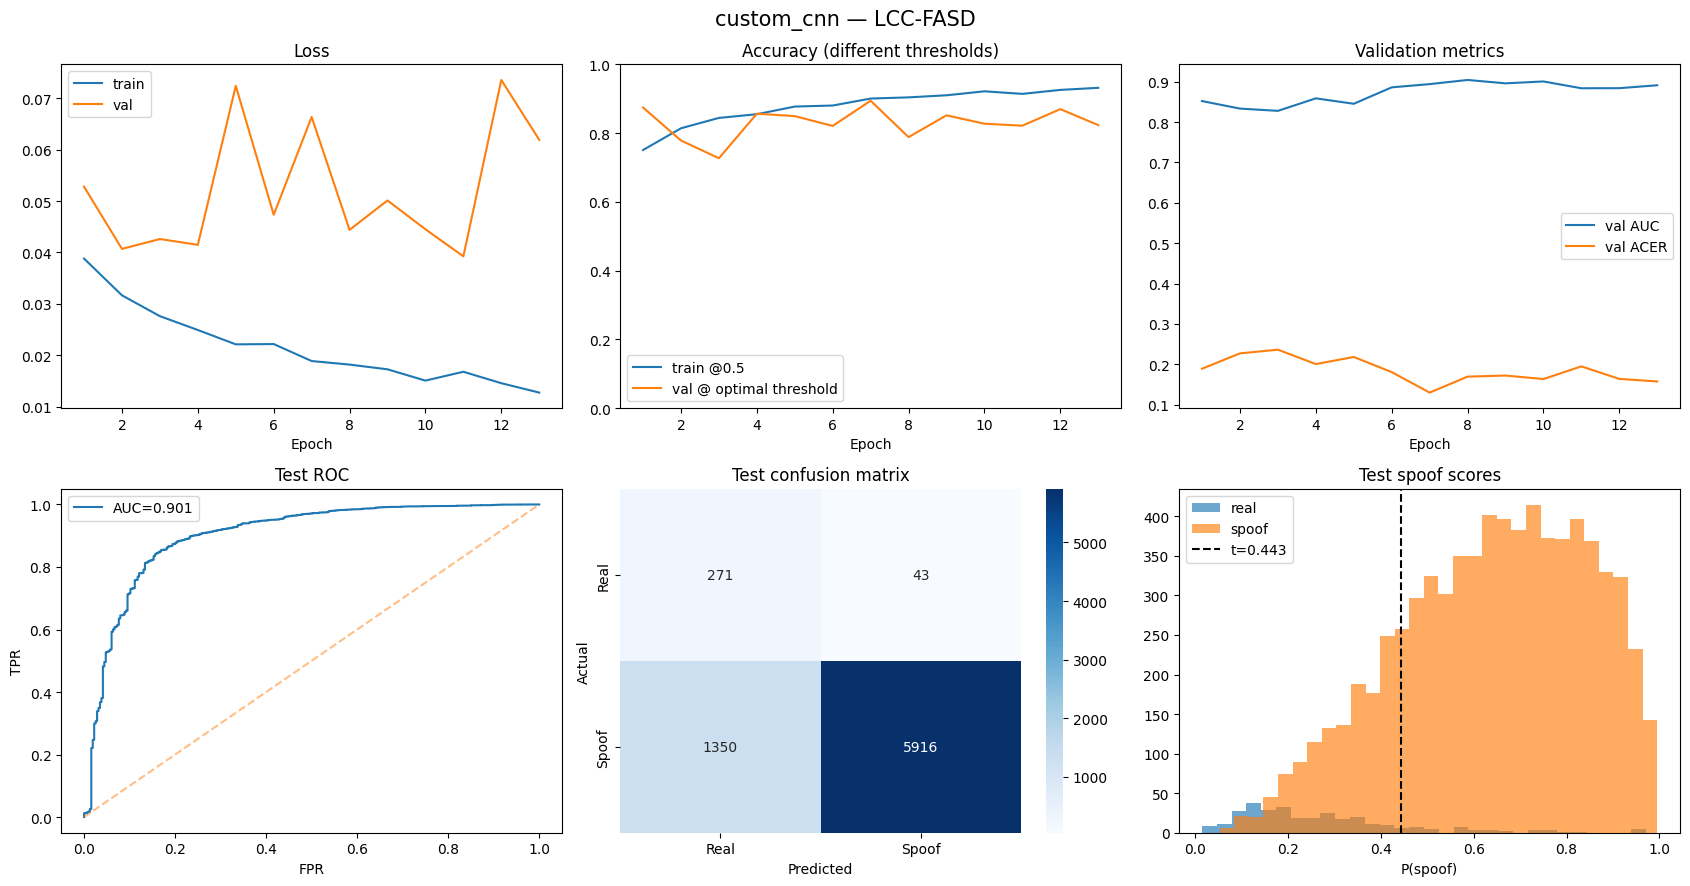

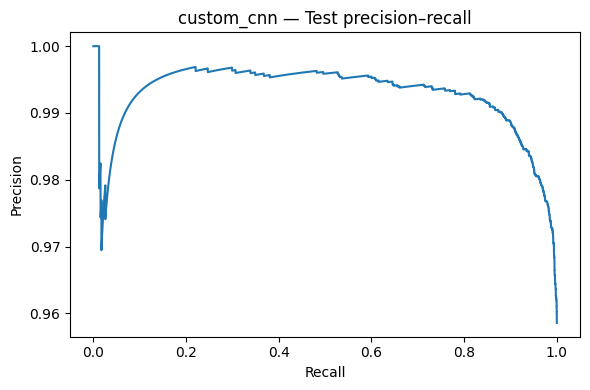

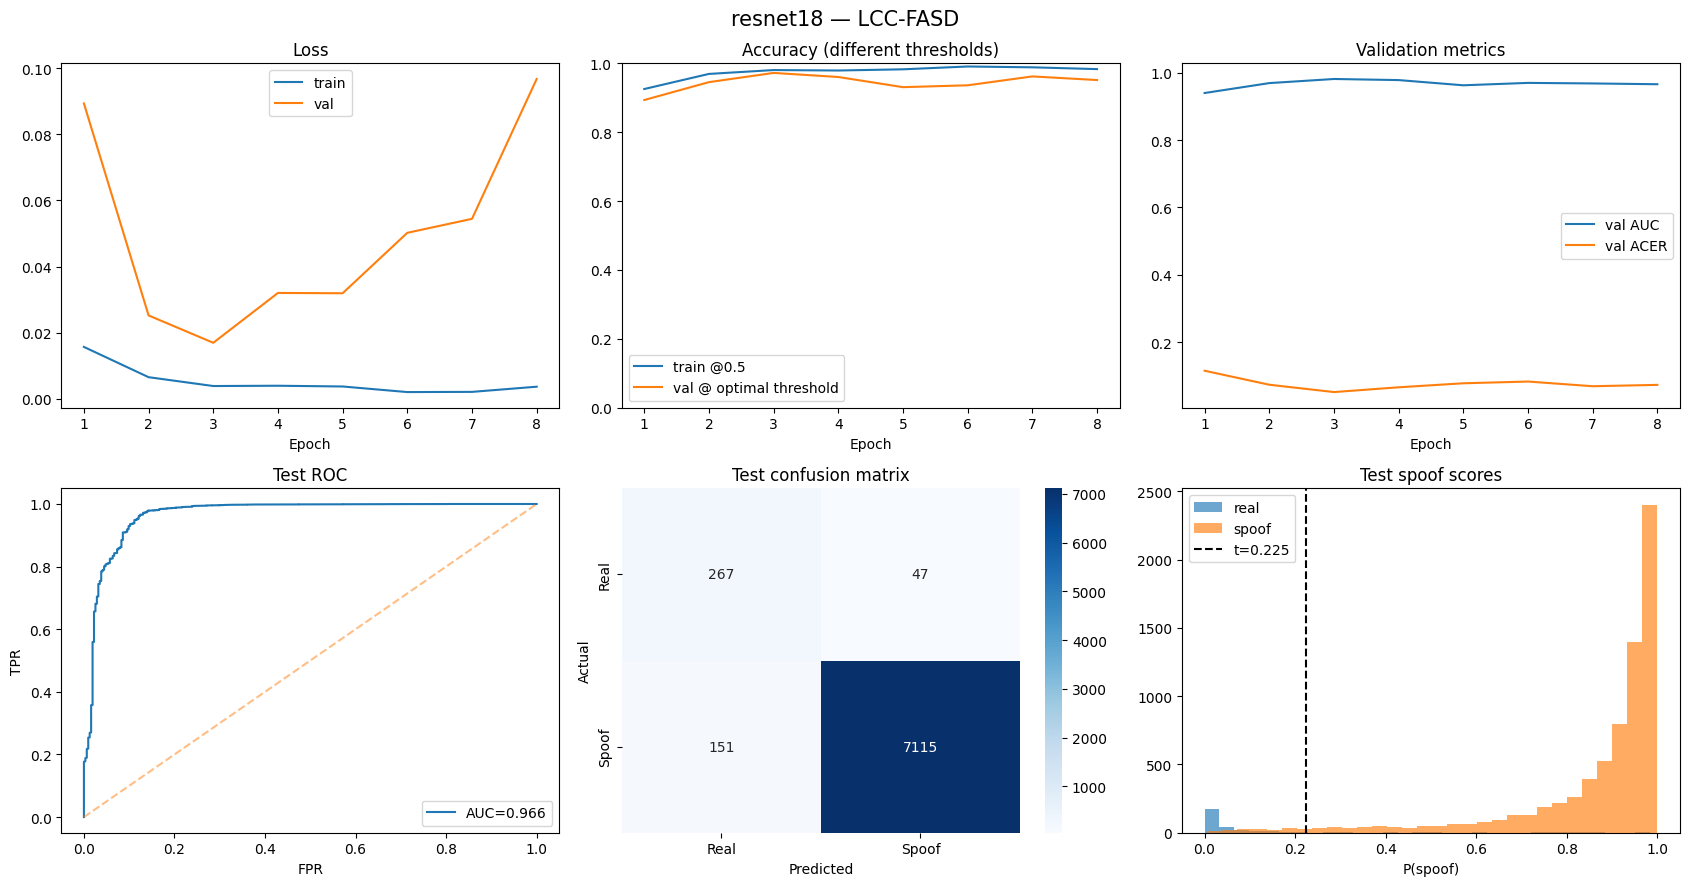

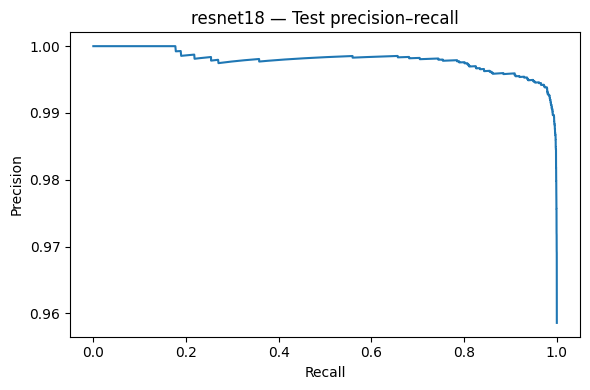

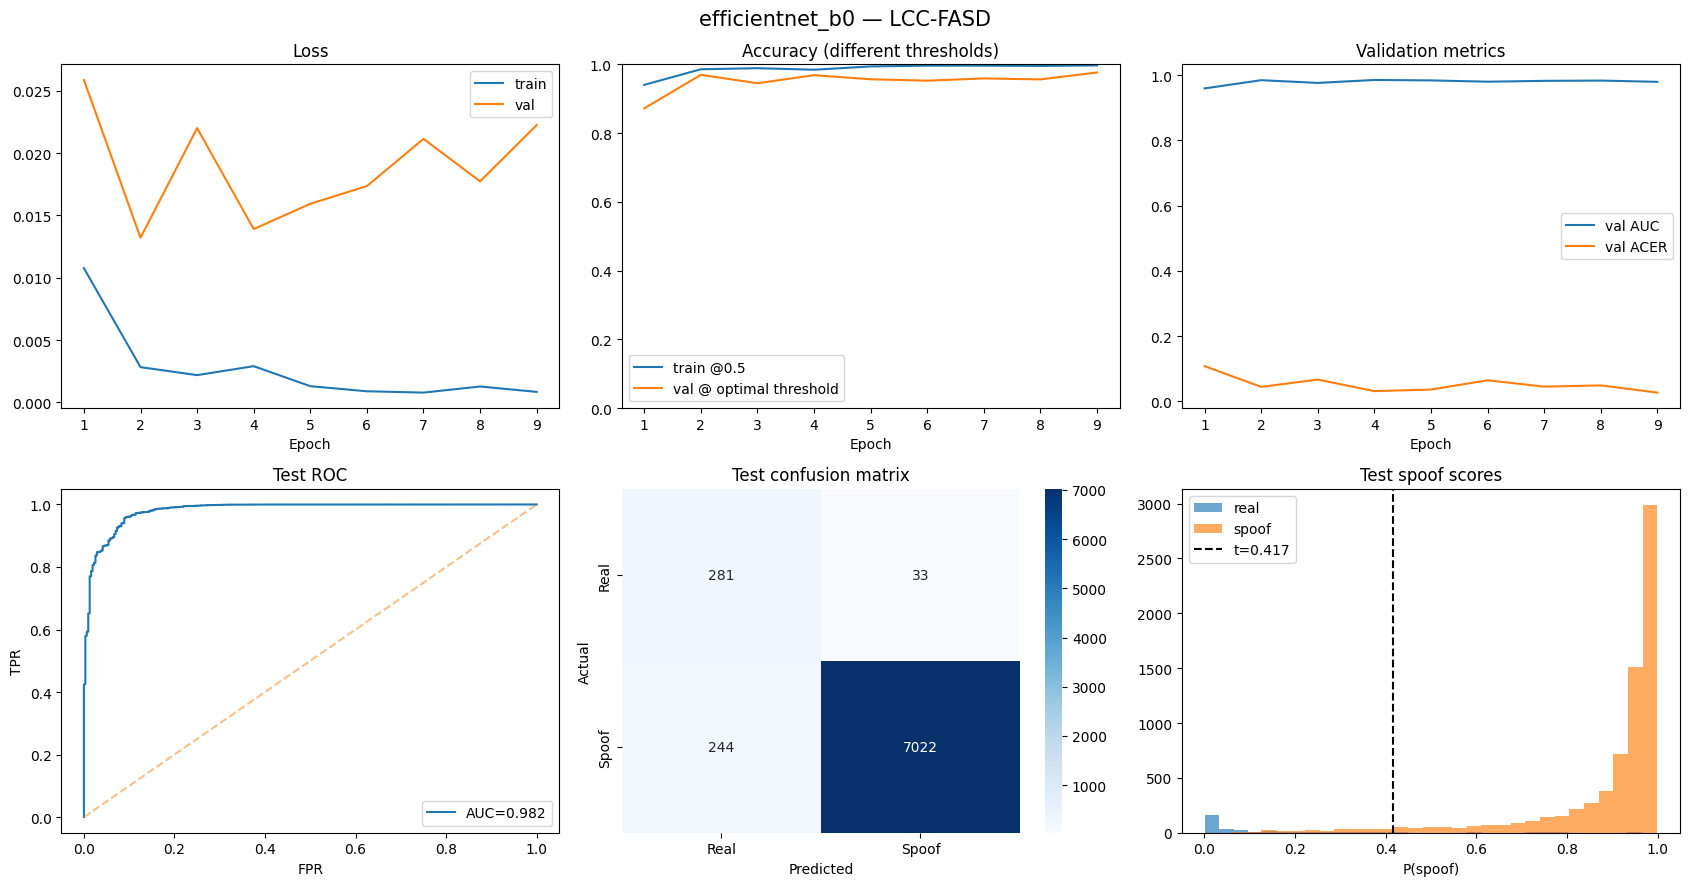

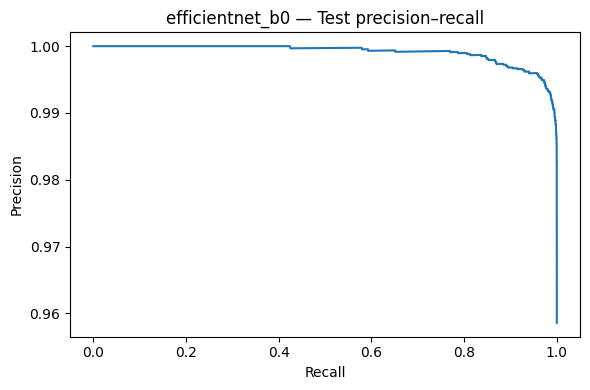

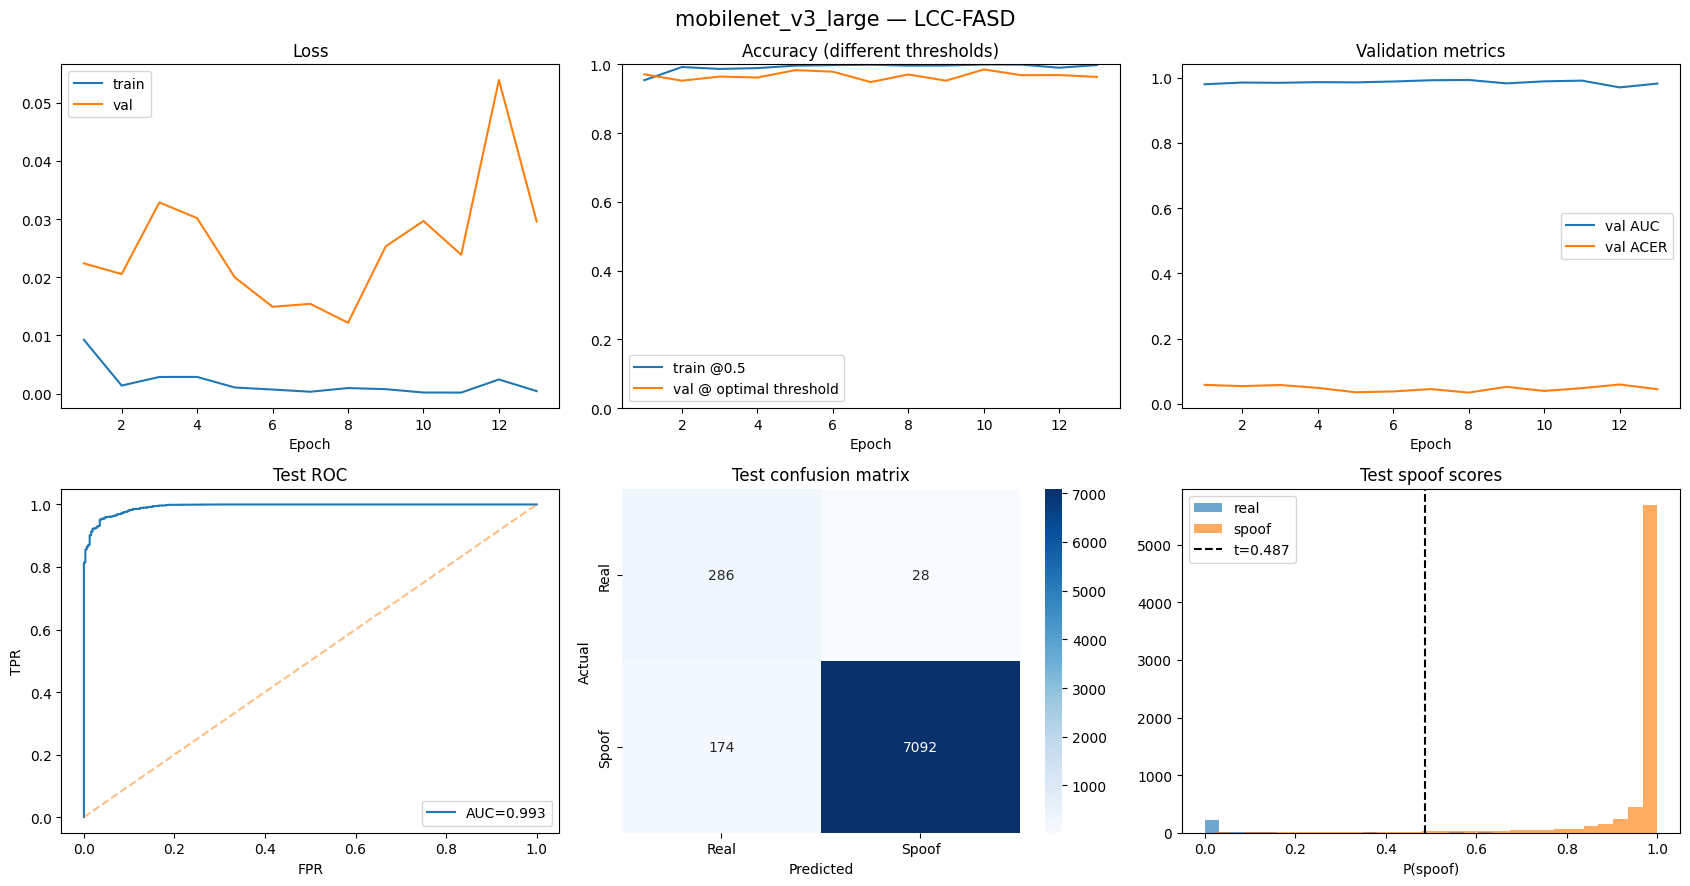

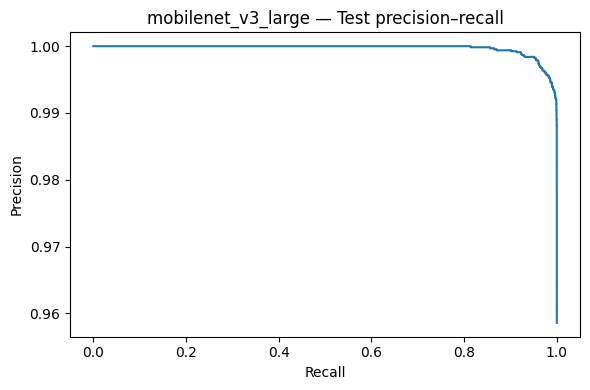

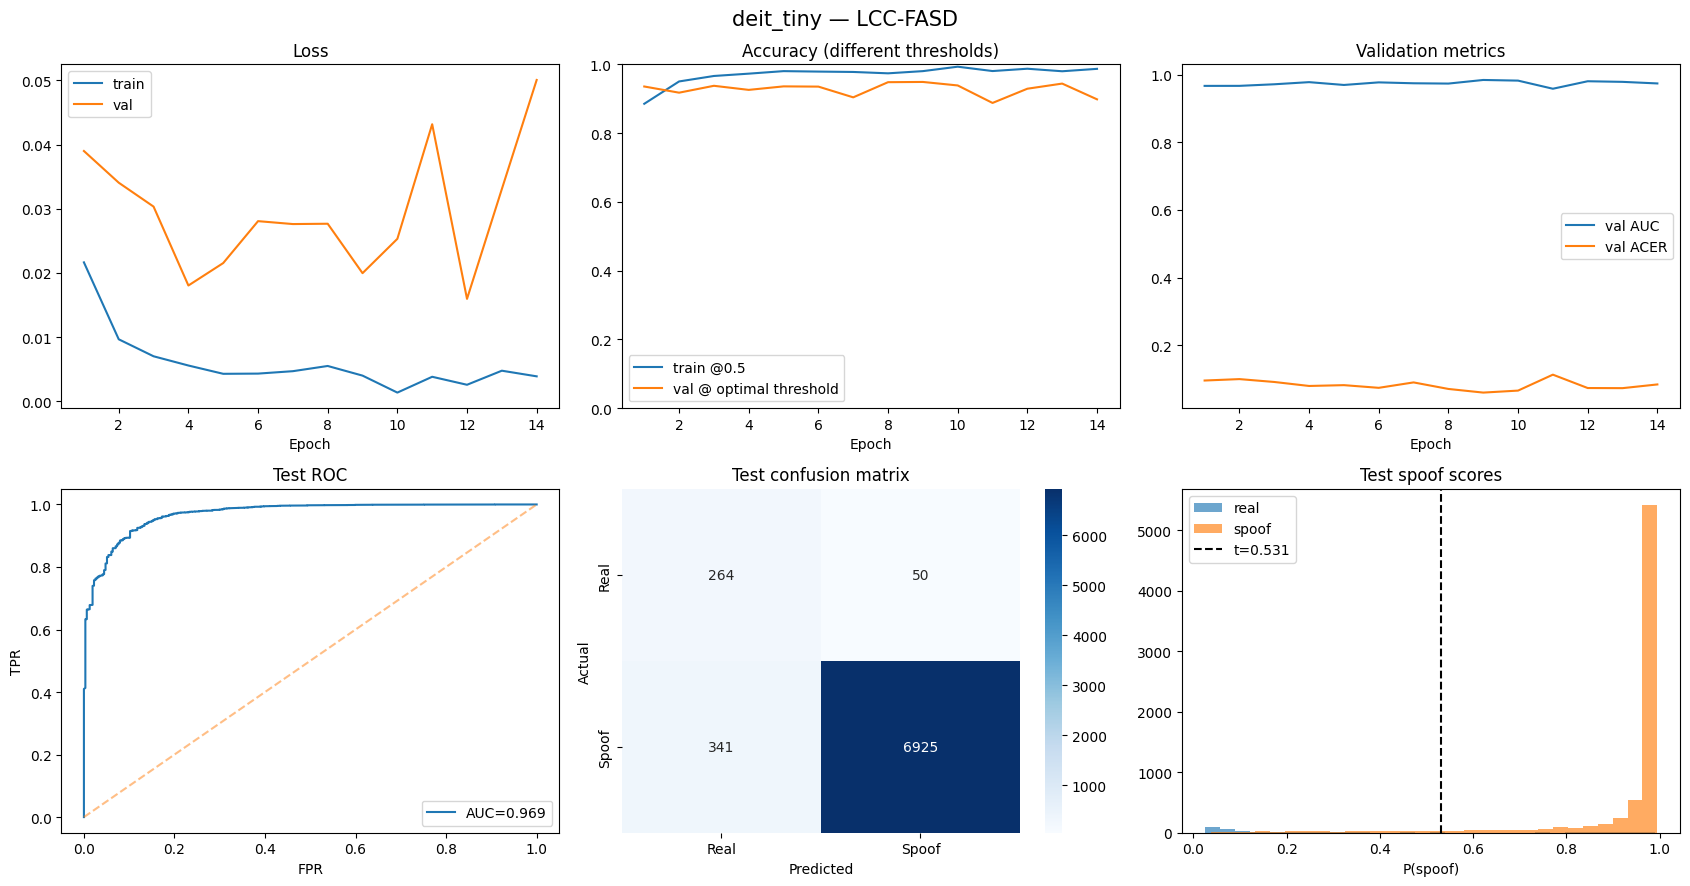

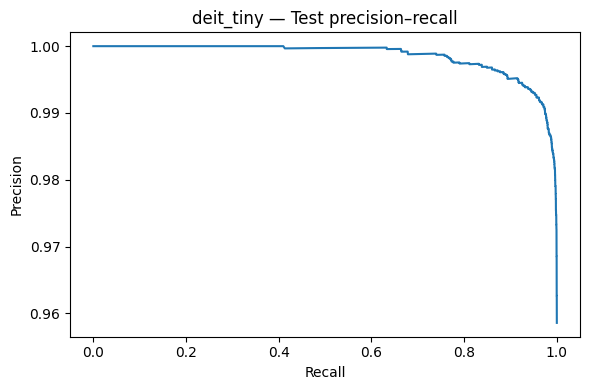

In [9]:
from sklearn.metrics import auc

def plot_one(name):
    out=RESULTS_DIR/name
    if not (out/'test_metrics.json').exists():
        print('No results for',name);return
    h=pd.read_csv(out/'history.csv');p=pd.read_csv(out/'test_predictions.csv');m=json.loads((out/'test_metrics.json').read_text())
    y=p['label'].to_numpy();scores=p['spoof_probability'].to_numpy();t=m['threshold']
    fig,axes=plt.subplots(2,3,figsize=(17,9))
    ax=axes[0,0];ax.plot(h.epoch,h.train_loss,label='train');ax.plot(h.epoch,h.val_loss,label='val');ax.set(title='Loss',xlabel='Epoch');ax.legend()
    ax=axes[0,1];ax.plot(h.epoch,h.train_accuracy,label='train @0.5');ax.plot(h.epoch,h.val_accuracy,label='val @ optimal threshold');ax.set(title='Accuracy (different thresholds)',xlabel='Epoch',ylim=(0,1));ax.legend()
    ax=axes[0,2];ax.plot(h.epoch,h.val_auc,label='val AUC');ax.plot(h.epoch,h.val_acer,label='val ACER');ax.set(title='Validation metrics',xlabel='Epoch');ax.legend()
    ax=axes[1,0];fpr,tpr,_=roc_curve(y,scores);ax.plot(fpr,tpr,label=f'AUC={m["roc_auc"]:.3f}');ax.plot([0,1],[0,1],'--',alpha=.5);ax.set(title='Test ROC',xlabel='FPR',ylabel='TPR');ax.legend()
    ax=axes[1,1];cm=confusion_matrix(y,(scores>=t).astype(int),labels=[0,1]);sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',ax=ax,xticklabels=['Real','Spoof'],yticklabels=['Real','Spoof']);ax.set(title='Test confusion matrix',xlabel='Predicted',ylabel='Actual')
    ax=axes[1,2];ax.hist(scores[y==0],bins=30,alpha=.65,label='real');ax.hist(scores[y==1],bins=30,alpha=.65,label='spoof');ax.axvline(t,linestyle='--',color='black',label=f't={t:.3f}');ax.set(title='Test spoof scores',xlabel='P(spoof)');ax.legend()
    fig.suptitle(name+' — LCC-FASD',fontsize=15);fig.tight_layout();fig.savefig(out/'training_and_evaluation.png',dpi=170);plt.show();plt.close(fig)
    precision,recall,_=precision_recall_curve(y,scores)
    fig,ax=plt.subplots(figsize=(6,4));ax.plot(recall,precision);ax.set(xlabel='Recall',ylabel='Precision',title=f'{name} — Test precision–recall');fig.tight_layout();fig.savefig(out/'precision_recall.png',dpi=170);plt.show();plt.close(fig)

for name in MODELS:plot_one(name)

## 9. Model comparison

The test split is heavily imbalanced (314 real, 7,266 spoof), so compare APCER, BPCER and ACER rather than accuracy.

,accuracy,precision,recall,f1,roc_auc,apcer,bpcer,acer,threshold,best_epoch,parameters
model,,,,,,,,,,,
custom_cnn,0.8162,0.9928,0.8142,0.8947,0.9005,0.1858,0.1369,0.1614,0.4427,8,315649
resnet18,0.9739,0.9934,0.9792,0.9863,0.9661,0.0208,0.1497,0.0852,0.2251,3,11177025
efficientnet_b0,0.9635,0.9953,0.9664,0.9807,0.9817,0.0336,0.1051,0.0693,0.4167,4,4008829
mobilenet_v3_large,0.9734,0.9961,0.9761,0.9860,0.9932,0.0239,0.0892,0.0566,0.4867,8,4203313
deit_tiny,0.9484,0.9928,0.9531,0.9725,0.9694,0.0469,0.1592,0.1031,0.5315,9,5524609


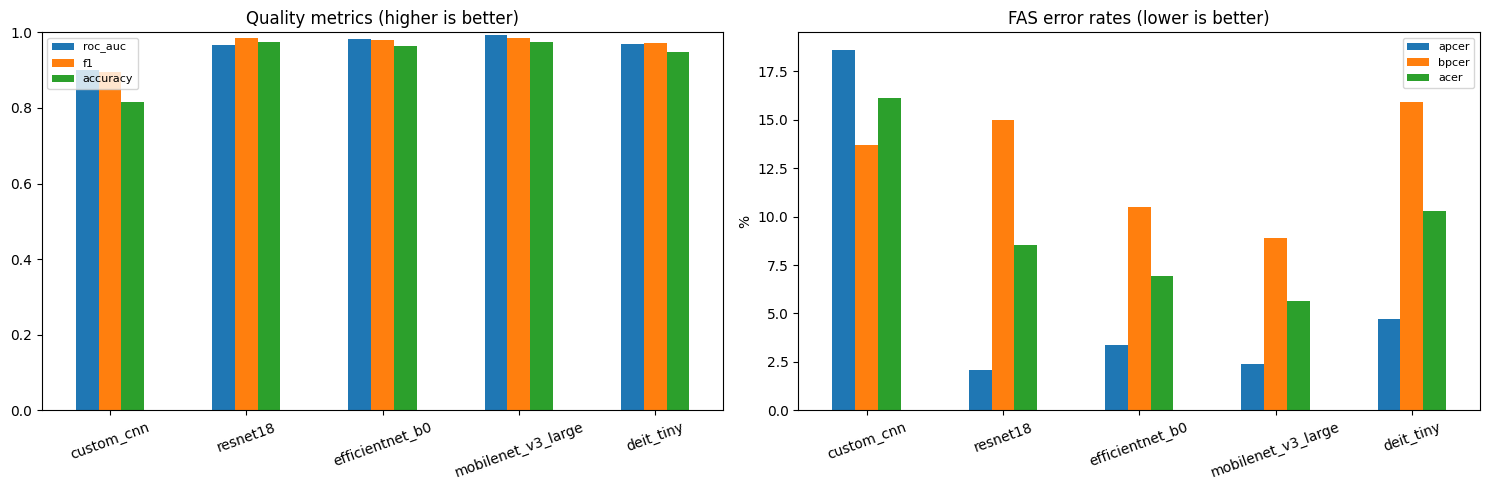

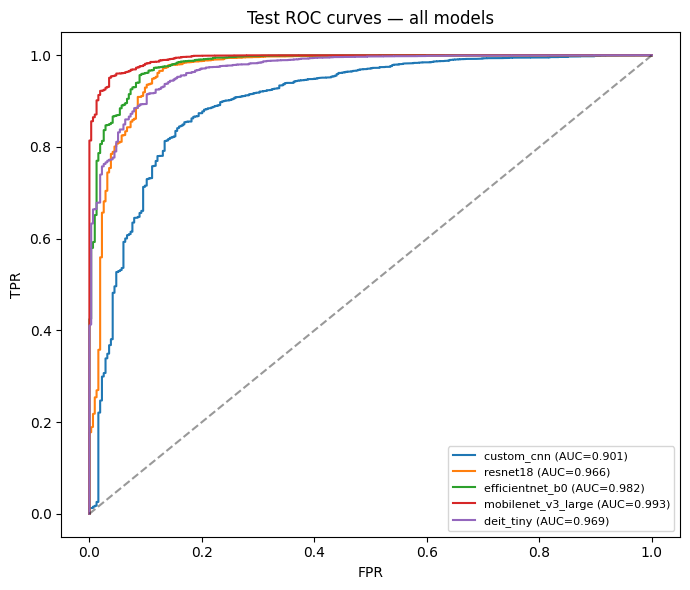

All results are on Google Drive: /content/drive/MyDrive/FaceAntiSpoofing/runs_lcc_fasd


In [12]:
rows=[]
for name in MODELS:
    file=RESULTS_DIR/name/'test_metrics.json'
    if file.exists(): rows.append(json.loads(file.read_text()))
if not rows: raise RuntimeError('No saved model results found')
summary=pd.DataFrame(rows).set_index('model').reindex(MODELS).dropna(how='all')
cols=['accuracy','precision','recall','f1','roc_auc','apcer','bpcer','acer','threshold','best_epoch','parameters']
display(summary[cols].round(4))
summary.to_csv(RESULTS_DIR/'model_comparison.csv')
fig,axes=plt.subplots(1,2,figsize=(15,5))
summary[['roc_auc','f1','accuracy']].plot.bar(ax=axes[0],ylim=(0,1),title='Quality metrics (higher is better)')
(summary[['apcer','bpcer','acer']]*100).plot.bar(ax=axes[1],title='FAS error rates (lower is better)')
axes[1].set_ylabel('%');
for ax in axes: ax.set_xlabel('');ax.tick_params(axis='x',rotation=20);ax.legend(fontsize=8)
plt.tight_layout();plt.savefig(RESULTS_DIR/'all_models_comparison.png',dpi=180);plt.show()
fig,ax=plt.subplots(figsize=(7,6))
for name in summary.index:
    df=pd.read_csv(RESULTS_DIR/name/'test_predictions.csv')
    fpr,tpr,_=roc_curve(df.label,df.spoof_probability)
    ax.plot(fpr,tpr,label=f'{name} (AUC={roc_auc_score(df.label,df.spoof_probability):.3f})')
ax.plot([0,1],[0,1],'k--',alpha=.4);ax.set(xlabel='FPR',ylabel='TPR',title='Test ROC curves — all models');ax.legend(fontsize=8)
plt.tight_layout();plt.savefig(RESULTS_DIR/'all_models_roc.png',dpi=180);plt.show()
print('All results are on Google Drive:',RESULTS_DIR)

## 10. Prediction on a new image

In [11]:
from PIL import Image
from IPython.display import display

def load_saved_model(model_name):
    folder=RESULTS_DIR/model_name
    model=build_model(model_name,pretrained=False).to(DEVICE)
    ckpt=torch.load(folder/'best.pt',map_location=DEVICE,weights_only=False)
    model.load_state_dict(ckpt['model']);model.eval()
    threshold=json.loads((folder/'threshold.json').read_text())['threshold']
    return model,threshold

@torch.no_grad()
def predict_image(image_path,model_name='mobilenet_v3_large'):
    model,threshold=load_saved_model(model_name)
    ds=FASImages([(Path(image_path),0)],train=False)
    x,_=ds[0]; x=x.unsqueeze(0).to(DEVICE)
    with torch.autocast(device_type=DEVICE.type,enabled=DEVICE.type=='cuda'):
        score=float(model(x).reshape(-1).sigmoid().item())
    return {'model':model_name,'spoof_probability':score,'threshold':threshold,'prediction':'SPOOF' if score>=threshold else 'REAL'}


In [13]:
image_path = "/content/drive/MyDrive/FaceAntiSpoofing/test_images/my_photo.jpg"

for model_name in MODELS:
    try:
        result = predict_image(image_path, model_name)
        print(result)
    except Exception as e:
        print(f"{model_name}: {e}")

{'model': 'custom_cnn', 'spoof_probability': 0.18994140625, 'threshold': 0.4426967203617096, 'prediction': 'REAL'}
{'model': 'resnet18', 'spoof_probability': 0.00908660888671875, 'threshold': 0.22507576644420624, 'prediction': 'REAL'}
{'model': 'efficientnet_b0', 'spoof_probability': 0.04052734375, 'threshold': 0.41673728823661804, 'prediction': 'REAL'}
{'model': 'mobilenet_v3_large', 'spoof_probability': 0.0001398324966430664, 'threshold': 0.4866516888141632, 'prediction': 'REAL'}
{'model': 'deit_tiny', 'spoof_probability': 0.1820068359375, 'threshold': 0.5314829349517822, 'prediction': 'REAL'}


## 11. Test-set examples

Correct and incorrect predictions for one model. Requires the dataset from section 2 to be unpacked in the current session.

Correct REAL (TN): 286 test images
Correct SPOOF (TP): 7092 test images
Spoof predicted REAL (FN / APCER): 174 test images
Real predicted SPOOF (FP / BPCER): 28 test images
Saved: /content/drive/MyDrive/FaceAntiSpoofing/runs_lcc_fasd/mobilenet_v3_large/test_prediction_examples.png


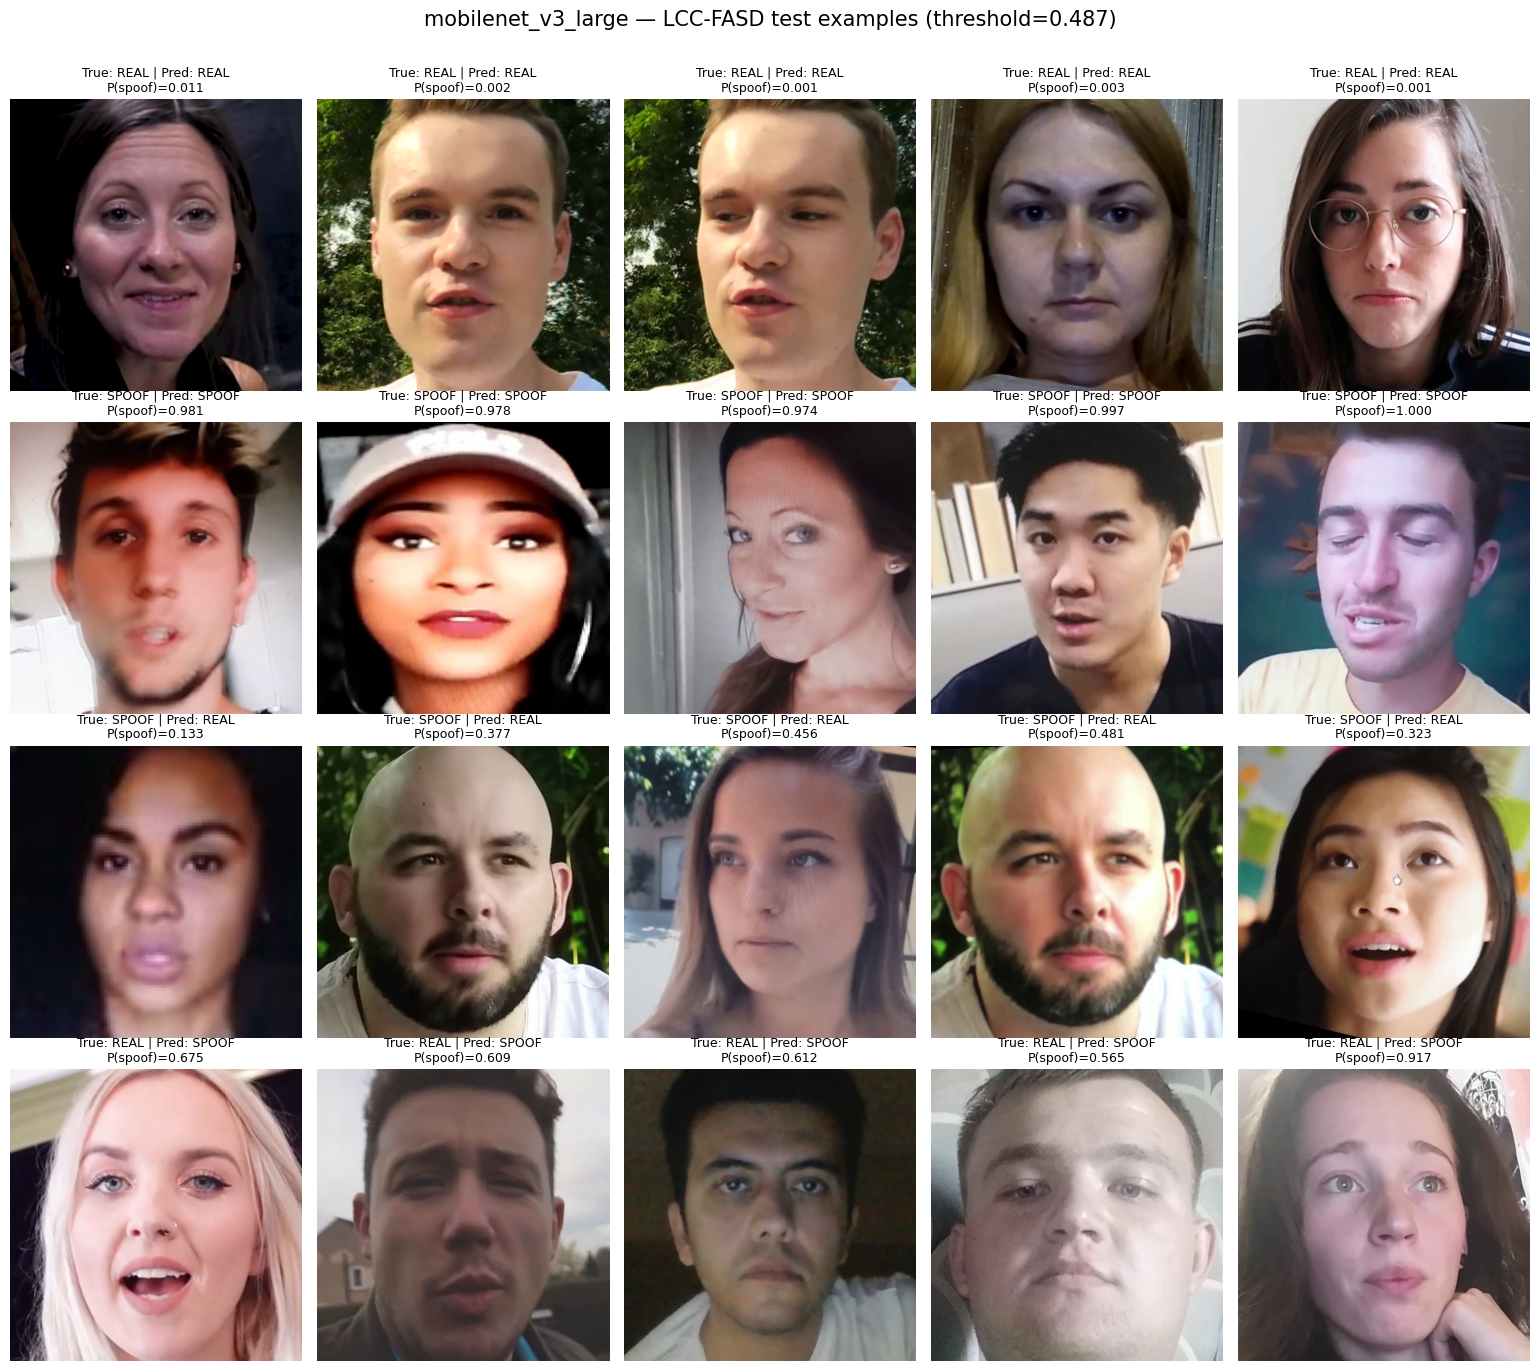

In [18]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

MODEL_TO_VIEW = 'mobilenet_v3_large'
N_PER_CATEGORY = 5
SELECTION = 'random'
RANDOM_SEED = 42
SAVE_FIGURE = True


def show_test_predictions(model_name=MODEL_TO_VIEW, n_per_category=N_PER_CATEGORY,
                          selection=SELECTION, seed=RANDOM_SEED, save=SAVE_FIGURE):
    folder = Path(RESULTS_DIR) / model_name
    csv_file = folder / 'test_predictions.csv'
    metrics_file = folder / 'test_metrics.json'
    if not csv_file.exists() or not metrics_file.exists():
        raise FileNotFoundError(f'No saved test predictions/metrics for {model_name}: {folder}')

    df = pd.read_csv(csv_file)
    threshold = float(json.loads(metrics_file.read_text())['threshold'])
    required = {'image_path', 'label', 'spoof_probability'}
    if not required.issubset(df.columns):
        raise ValueError(f'Missing columns: {required - set(df.columns)}')
    df['label'] = df['label'].astype(int)
    df['pred'] = (df['spoof_probability'] >= threshold).astype(int)
    df['distance'] = (df['spoof_probability'] - threshold).abs()

    original_paths = [Path(p) for p in df['image_path']]
    if not all(p.is_file() for p in original_paths):
        if 'SPLITS' not in globals() or 'test' not in SPLITS or len(SPLITS['test']) != len(df):
            raise FileNotFoundError('Image files are no longer in /content. Rerun dataset setup and split-loading cells, then retry.')
        refreshed = [Path(p) for p, _ in SPLITS['test']]
        actual_labels = [int(y) for _, y in SPLITS['test']]
        if actual_labels != df['label'].tolist():
            raise ValueError('The current test split order/labels differ from saved CSV. Refusing to associate predictions with incorrect images.')
        if any(old.name != new.name for old, new in zip(original_paths, refreshed)):
            raise ValueError('Current test image filenames differ from saved CSV; cannot safely display predictions.')
        df['image_path'] = [str(p) for p in refreshed]

    groups = [
        ('Correct REAL (TN)', (df.label == 0) & (df.pred == 0)),
        ('Correct SPOOF (TP)', (df.label == 1) & (df.pred == 1)),
        ('Spoof predicted REAL (FN / APCER)', (df.label == 1) & (df.pred == 0)),
        ('Real predicted SPOOF (FP / BPCER)', (df.label == 0) & (df.pred == 1)),
    ]
    fig, axes = plt.subplots(4, n_per_category, figsize=(3.1 * n_per_category, 14), squeeze=False)
    rng = np.random.default_rng(seed)
    for row_idx, (title, mask) in enumerate(groups):
        subset = df.loc[mask].copy()
        print(f'{title}: {len(subset)} test images')
        if selection == 'random':
            sampled = subset.iloc[rng.permutation(len(subset))[:n_per_category]]
        elif selection == 'closest_to_threshold':
            sampled = subset.sort_values('distance', ascending=True).head(n_per_category)
        elif selection == 'most_confident':
            sampled = subset.sort_values('distance', ascending=False).head(n_per_category)
        else:
            raise ValueError("selection must be 'random', 'most_confident', or 'closest_to_threshold'")
        for col_idx, ax in enumerate(axes[row_idx]):
            ax.axis('off')
            if col_idx >= len(sampled):
                continue
            item = sampled.iloc[col_idx]
            path = Path(item.image_path)
            if not path.is_file():
                ax.set_title('Missing image', fontsize=9)
                continue
            with Image.open(path) as im:
                ax.imshow(im.convert('RGB'))
            true_name = 'SPOOF' if item.label else 'REAL'
            pred_name = 'SPOOF' if item.pred else 'REAL'
            ax.set_title(f'True: {true_name} | Pred: {pred_name}\nP(spoof)={item.spoof_probability:.3f}', fontsize=9)
            if col_idx == 0:
                ax.set_ylabel(title, fontsize=10)
    fig.suptitle(f'{model_name} — LCC-FASD test examples (threshold={threshold:.3f})', fontsize=15)
    plt.tight_layout(rect=(0, 0, 1, 0.97))
    if save:
        out_file = folder / 'test_prediction_examples.png'
        fig.savefig(out_file, dpi=160, bbox_inches='tight')
        print('Saved:', out_file)
    plt.show()
    plt.close(fig)

show_test_predictions()
